# Temperature and New York City electricity demand
## tl;dr
**A small nonlinear temperature model materially improved estimates on 2025 data excluded from fitting and model selection.** Calendar-only MAE was **436 MW**, linear-temperature MAE **443 MW**, and spline MAE **265 MW**: a **39.2% reduction** versus the calendar baseline. The spline improved MAE in all twelve months. During 472 hot hours (temperature ≥28.3°C), MAE fell from 1,136 to 511 MW.

This is a **retrospective conditional demand model using observed weather**, not an operational day-ahead forecast, causal estimate, trading strategy, or corporate-loss model. Errors remain substantial and dependent; the spline underestimates demand by 109 MW on average. All headline values below are recalculated from cached real data.

## Context & Methods
The question is whether hourly temperature adds information beyond a reasonably capable calendar baseline, and whether a simple nonlinear response helps further. Electricity demand is economically relevant to energy planning and weather sensitivity. No financial-loss or revenue conversion is attempted.

Development fitting: **2021–2023**. Complexity selection: **2024**. Final evaluation: **2025**, after refitting on 2021–2024. The nonlinear model is an ordinary least-squares regression with a continuous piecewise-linear temperature spline. Its 3- versus 5-knot choice uses validation MAE only. All models share 221 calendar columns: hour of week, annual Fourier terms, hour-by-annual interactions, and observed federal holidays. Linear and spline models have 222 and 225 fitted coefficients respectively.

### Key Assumptions
- One LaGuardia station is a proxy for the whole NYC load zone. Humidity, thermal lags, and other demand drivers are omitted.
- NYISO's hour-beginning load is matched to a routine weather report within that UTC hour. This is an hourly weather proxy, not an exact temperature integral.
- Missing and quality-rejected weather hours are excluded from every model equally. No imputation. A 90-hour gap crosses August/September 2025; missingness could be selective.
- Data were downloaded retrospectively and may include revisions. Calendar-year separation does not establish prospective forecast performance.
- Paired daily block bootstrap intervals characterize this test year's errors, not parameter uncertainty or all future years.

The complete frozen specification is [EXPERIMENT.md](EXPERIMENT.md). Module code is in `src/`; source URLs and hashes are in `raw/manifest.json`. This notebook mechanically reruns the same frozen comparison; it does not tune on final results.

### 1. Setup and reproduce the experiment

In [1]:
from pathlib import Path
import sys, json, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'EXPERIMENT.md').exists():
    ROOT = ROOT / 'NYC_Weather_Electricity'
assert (ROOT / 'EXPERIMENT.md').exists(), 'Run from the project or its parent directory.'
sys.path.insert(0, str(ROOT / 'src'))
from run import main
with contextlib.redirect_stdout(io.StringIO()):
    main()  # Cached-source preparation, validation selection, refit, and frozen evaluation.
OUT = ROOT / 'outputs'
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'axes.axisbelow': True, 'savefig.dpi': 150})
COLORS = {'calendar': '#52616b', 'linear': '#b5791b', 'spline': '#2166ac'}
LABELS = {'calendar': 'Calendar', 'linear': '+ Linear temperature', 'spline': '+ Temperature spline'}
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, bbox_inches='tight')
    plt.show()
print('Frozen experiment reproduced from cached NYISO and NOAA source files.')

Frozen experiment reproduced from cached NYISO and NOAA source files.


## Data
[NYISO Integrated Real-Time Actual Load](https://mis.nyiso.com/public/P-58Clist.htm): N.Y.C., PTID 61761, time-weighted hourly load in MW, with explicit EST/EDT offsets. [NOAA GHCNh](https://www.ncei.noaa.gov/products/global-historical-climatology-network-hourly): USW00014732, LaGuardia Airport, 40.7794°N, 73.8803°W. NOAA's retired ISD CSV URLs returned HTML; the documented successor supplies full 2025 observations.

Routine METAR FM15 is preferred over SYNOP FM12; event-driven SPECI reports are excluded. Quality codes are interpreted by source, including source 343's code 5 (passed all checks). Dates are joined in UTC and calendar features use New York local time. The final five hours of local 2025 come from the 2026 UTC weather file; later 2026 data are never used.

### 2. Coverage and exclusions

In [2]:
coverage = pd.read_csv(OUT / 'annual_coverage.csv')
quality = json.loads((OUT / 'feasibility.json').read_text())
display(coverage.assign(coverage_pct=coverage.coverage * 100).drop(columns='coverage').round(3))
print(f"Matched {quality['matched_hours']:,} of {quality['expected_hours']:,} expected hours; "
      f"{quality['excluded_hours']} excluded. Longest missing run: {quality['longest_missing_run_hours']} hours.")
display(pd.read_csv(OUT / 'missing_runs.csv').head(3))
predictions = pd.read_csv(OUT / 'test_predictions.csv', parse_dates=['utc'])
scores = pd.read_csv(OUT / 'test_metrics.csv')
configuration = json.loads((OUT / 'selected_configuration.json').read_text())
assert predictions.year.eq(2025).all() and not predictions.utc.duplicated().any()
assert configuration['selected_spline_knots'] == 3

,year,expected_hours,load_hours,weather_hours,joined_hours,coverage_pct
0,2021,8760,8760,8755,8755,99.943
1,2022,8760,8760,8754,8754,99.932
2,2023,8760,8760,8759,8759,99.989
3,2024,8784,8784,8778,8778,99.932
4,2025,8760,8760,8654,8654,98.790


Matched 43,700 of 43,824 expected hours; 124 excluded. Longest missing run: 90 hours.


,start_utc,end_utc,hours
0,2025-08-29 23:00:00+00:00,2025-09-02 16:00:00+00:00,90
1,2024-12-03 17:00:00+00:00,2024-12-03 20:00:00+00:00,4
2,2021-02-08 14:00:00+00:00,2021-02-08 16:00:00+00:00,3


### 3. Representative observed period — fixed before evaluation

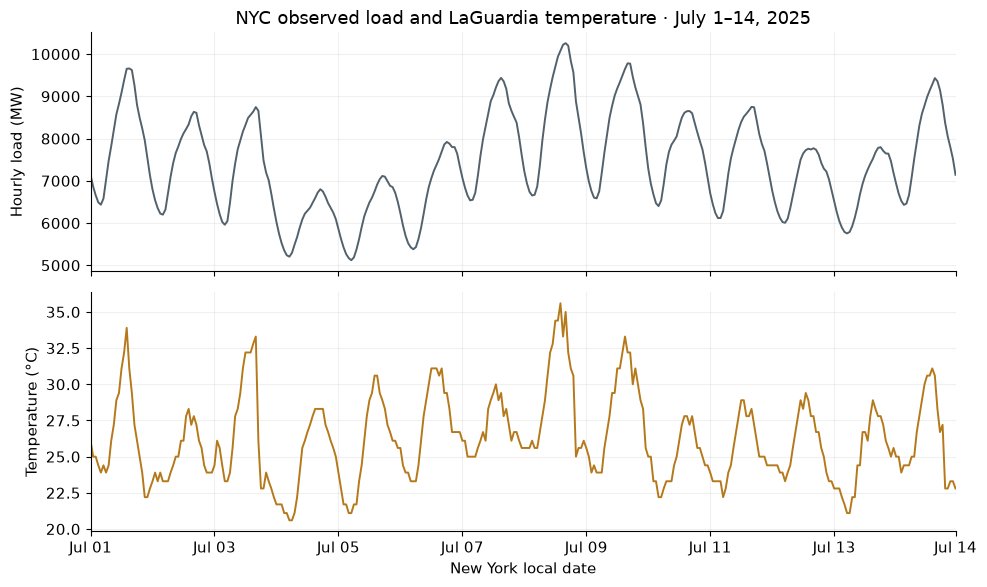

In [3]:
period = predictions.loc[(predictions.utc >= '2025-07-01T04:00:00Z') &
                         (predictions.utc < '2025-07-15T04:00:00Z')].copy()
local = period.utc.dt.tz_convert('America/New_York')
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(local, period.load_mw, color=COLORS['calendar'], linewidth=1.4)
axes[0].set(ylabel='Hourly load (MW)', title='NYC observed load and LaGuardia temperature · July 1–14, 2025')
axes[1].plot(local, period.temperature_c, color=COLORS['linear'], linewidth=1.4)
axes[1].set(ylabel='Temperature (°C)', xlabel='New York local date')
ticks = list(pd.date_range(local.iloc[0].normalize(), local.iloc[-1].normalize(), freq='2D'))
if ticks[-1].date() != local.iloc[-1].date():
    ticks.append(local.iloc[-1])
axes[1].set_xticks(ticks)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d', tz=local.dt.tz))
axes[1].set_xlim(local.iloc[0], local.iloc[-1])
save_figure(fig, '01_observed_period.png')

The selected two-week display illustrates daily load cycles and weather variation. It is descriptive; the evaluation uses the whole matched 2025 year, not just this chart.

## Results
### 4. Validation and final evaluation
Spline complexity was selected with 2024 MAE: 3 knots scored 226.812 MW versus 226.929 MW for 5 knots. The small difference does not establish a scientifically meaningful advantage of three knots; it determines the fixed choice under the protocol.

,model,hours,mae_mw,rmse_mw,mean_residual_mw
0,calendar,8778,351.812,513.080,68.653
1,linear,8778,364.075,506.900,66.970
2,spline_3,8778,226.812,331.484,82.799
3,spline_5,8778,226.929,331.257,83.073


,hours,mae_mw,rmse_mw,mean_residual_mw,mae_improvement_pct
model,,,,,
calendar,8654,436.38,602.35,125.76,0.00
linear,8654,442.99,598.08,145.74,-1.51
spline,8654,265.13,359.68,109.42,39.24


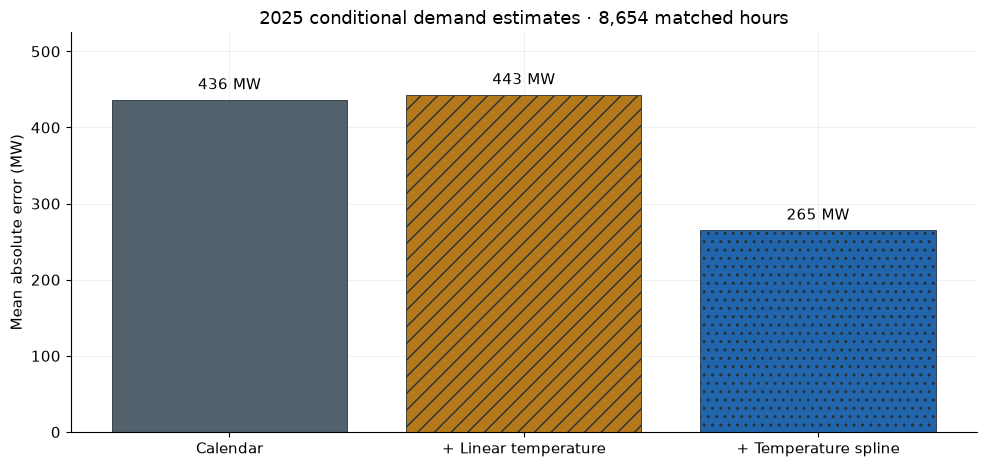

In [4]:
display(pd.read_csv(OUT / 'validation_metrics.csv').round(3))
overall = scores.loc[scores.group_type.eq('overall')].set_index('model').loc[list(LABELS)]
display(overall[['hours', 'mae_mw', 'rmse_mw', 'mean_residual_mw', 'mae_improvement_pct']].round(2))
fig, ax = plt.subplots()
bars = ax.bar([LABELS[k] for k in LABELS], overall.mae_mw,
              color=[COLORS[k] for k in LABELS], edgecolor='#263238', linewidth=.6,
              hatch=['', '//', '..'])
ax.bar_label(bars, fmt='%.0f MW', padding=5)
ax.set(ylabel='Mean absolute error (MW)', title='2025 conditional demand estimates · 8,654 matched hours', ylim=(0, 525))
save_figure(fig, '03_model_errors.png')

The nonlinear model's overall MAE improvement is **171 MW (39.2%)**. Linear temperature alone slightly worsens MAE, even though its RMSE is slightly lower. A single straight-line temperature effect is insufficient in this specification. These comparisons are against the stated calendar baseline, not against commercial forecasting systems or every possible model.

### 5. Adjusted temperature-response curve

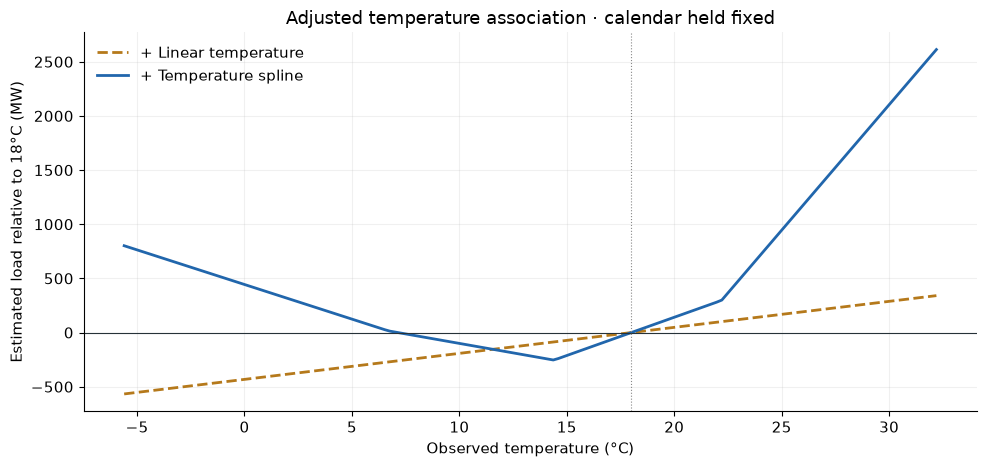

Shown range: -5.6–32.2°C, fitting-sample 1st–99th percentiles.


In [5]:
curve = pd.read_csv(OUT / 'temperature_response.csv')
fig, ax = plt.subplots()
for name, style in [('linear', '--'), ('spline', '-')]:
    ax.plot(curve.temperature_c, curve[name + '_relative_mw'], label=LABELS[name],
            color=COLORS[name], linestyle=style, linewidth=2)
ax.axhline(0, color='#263238', linewidth=.8)
ax.axvline(18, color='#888888', linewidth=.8, linestyle=':')
ax.set(xlabel='Observed temperature (°C)', ylabel='Estimated load relative to 18°C (MW)',
       title='Adjusted temperature association · calendar held fixed')
ax.legend(frameon=False)
save_figure(fig, '02_temperature_response.png')
print(f"Shown range: {curve.temperature_c.min():.1f}–{curve.temperature_c.max():.1f}°C, fitting-sample 1st–99th percentiles.")

The spline allows separate cold and hot responses. The curve is the fitted association relative to 18°C with identical calendar conditions. It does not establish causality, and temperatures outside this fitting range are not shown. The model has no temperature-by-hour interaction, so it assumes a common additive temperature response across calendar conditions.

### 6. Hot-hour performance

,hours,mae_mw,rmse_mw,mean_residual_mw,mae_improvement_pct
model,,,,,
calendar,472,1136.38,1377.12,1036.67,0.00
linear,472,1056.97,1284.07,947.77,6.99
spline,472,511.30,648.78,161.14,55.01


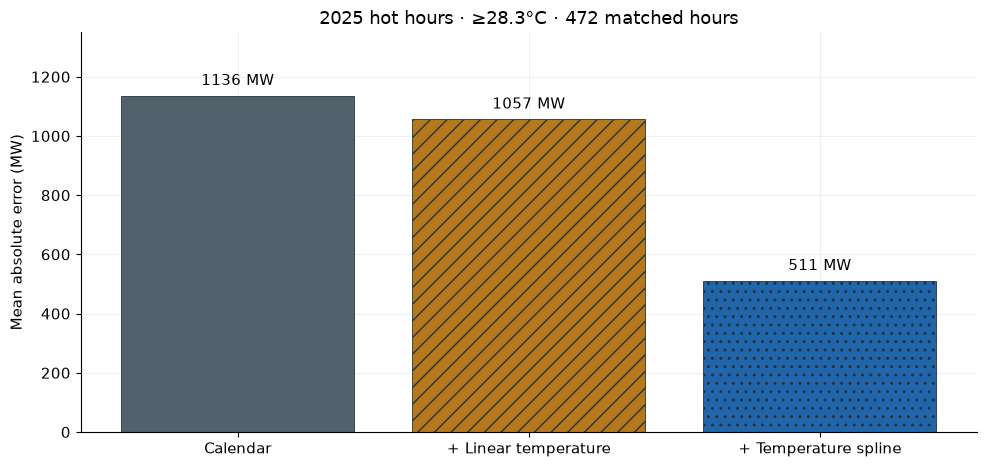

In [6]:
hot = scores.loc[scores.group_type.eq('temperature') & scores.group.eq('hot')].set_index('model').loc[list(LABELS)]
display(hot[['hours', 'mae_mw', 'rmse_mw', 'mean_residual_mw', 'mae_improvement_pct']].round(2))
fig, ax = plt.subplots()
bars = ax.bar([LABELS[k] for k in LABELS], hot.mae_mw,
              color=[COLORS[k] for k in LABELS], edgecolor='#263238', linewidth=.6,
              hatch=['', '//', '..'])
ax.bar_label(bars, fmt='%.0f MW', padding=5)
ax.set(ylabel='Mean absolute error (MW)', title=f"2025 hot hours · ≥{configuration['hot_threshold_c_from_2021_2023']:.1f}°C · 472 matched hours", ylim=(0, 1350))
save_figure(fig, '04_hot_hour_errors.png')

Hot is defined by the **2021–2023 95th-percentile threshold**, not by optimizing a 2025 cutoff. Hot-hour MAE improves by 55.0%, but **511 MW of remaining MAE** is substantial. There is no separate hot-hour significance claim, and missing-weather hours are not represented.

### 7. Stability, uncertainty, and remaining structure

In [7]:
monthly = scores.loc[scores.group_type.eq('month')].pivot(index='group', columns='model', values='mae_mw')
monthly.index = monthly.index.astype(int); monthly = monthly.sort_index()
monthly['spline_improvement_pct'] = 100 * (monthly.calendar - monthly.spline) / monthly.calendar
display(monthly.round(2))
intervals = pd.read_csv(OUT / 'uncertainty.csv')
display(intervals.round(2))
display(pd.read_csv(OUT / 'residual_diagnostics.csv').round(3))
assert monthly.spline.lt(monthly.calendar).all()

model,calendar,linear,spline,spline_improvement_pct
group,,,,
1,471.20,546.40,295.43,37.30
2,376.90,458.69,218.36,42.07
3,154.01,212.62,130.93,14.99
4,203.41,220.78,184.65,9.22
5,335.45,275.99,230.76,31.21
6,839.19,757.90,426.97,49.12
7,669.20,636.35,426.74,36.23
8,839.35,783.45,444.54,47.04
9,499.34,444.85,260.92,47.75


,comparison,block_days,mean_improvement_mw,lower_95_mw,upper_95_mw,calendar_days,days_with_observations
0,calendar minus linear,7,-6.61,-24.89,12.05,365,362
1,calendar minus linear,14,-6.61,-30.95,17.60,365,362
2,calendar minus linear,28,-6.61,-40.17,28.18,365,362
3,calendar minus spline,7,171.24,128.70,220.19,365,362
4,calendar minus spline,14,171.24,116.03,229.96,365,362
5,calendar minus spline,28,171.24,106.16,239.43,365,362


,model,lag_hours,correlation,paired_hours
0,calendar,1,0.995,8640
1,calendar,24,0.727,8593
2,calendar,168,0.161,8384
3,linear,1,0.994,8640
4,linear,24,0.726,8593
5,linear,168,0.172,8384
6,spline,1,0.952,8640
7,spline,24,0.581,8593
8,spline,168,0.175,8384


The spline improves MAE in **12 of 12 months**, with monthly gains ranging from 9.2% to 49.1%. The paired seven-day block-bootstrap 95% interval for the overall improvement is **129–220 MW**; the 14- and 28-day intervals also remain positive. The linear model's interval crosses zero. Block resampling respects some daily dependence, but is an approximate description of one test year, not proof of permanent reliability.

The spline's residuals remain highly dependent: lag-1 correlation **0.952**, lag-24 **0.581**, and lag-168 **0.175**. Mean residual (actual minus estimated) is **+109 MW**, indicating average underestimation. These are material limits. Humidity, thermal inertia, calendar closures, and changing demand levels are possible omitted factors; this project does not establish which explains the errors.

## Takeaways
**Useful result:** a small, interpretable nonlinear temperature term adds substantial information beyond the specified calendar baseline on a later calendar year. Adding temperature linearly does not deliver the same result. The project demonstrates source validation, UTC/DST handling, leakage-safe fitting, model comparison, dependence-aware evaluation, and economic interpretation in Python.

**Practical boundary:** this is one city/zone, one station, five retrospective years, and one final evaluation year. It is not an operational forecast, a causal weather-impact model, a climate scenario model, or a financial-loss model. No novelty claim is made for temperature-sensitive electricity demand. The remaining bias, serial dependence, station representativeness, and missing-weather gap limit broader claims.

**Stopping point reached:** the three-model comparison is complete. Keep Baxter as the separate financial evidence project. Further modeling would need a specific new question rather than additional complexity to improve presentation.

To reproduce: install `requirements.txt`, run `python src/acquire.py --full` if raw files are absent, run `python src/run.py`, and execute this notebook from the project folder. Tests: `python -m unittest discover -s tests -v`. No credentials are required. Source records are preserved in `SOURCES.md` and `raw/manifest.json`.